# E-commerce Recommendation System — Exploratory Data Analysis

## Objective

Analyze the Retailrocket e-commerce interaction data to understand:

- user behavior
- product interactions
- event types
- interaction frequency
- temporal patterns
- data quality
- user-item interaction sparsity

These findings will guide the design of the content-based, collaborative filtering, and hybrid recommendation models.

## 1. Import Libraries

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Load Raw Event Data

In [2]:
events = pd.read_csv("../data/raw/events.csv")
events.head()

,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908,NaN
1,1433224214164,992329,view,248676,NaN
2,1433221999827,111016,view,318965,NaN
3,1433221955914,483717,view,253185,NaN
4,1433221337106,951259,view,367447,NaN


## 3. Initial Data Inspection

In [3]:
print("Dataset shape:", events.shape)
print("\nColumns:")
print(events.columns.tolist())

Dataset shape: (2756101, 5)

Columns:
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']


In [4]:
events.info()

<class 'pandas.DataFrame'>
RangeIndex: 2756101 entries, 0 to 2756100
Data columns (total 5 columns):
 #   Column         Dtype  
---  ------         -----  
 0   timestamp      int64  
 1   visitorid      int64  
 2   event          str    
 3   itemid         int64  
 4   transactionid  float64
dtypes: float64(1), int64(3), str(1)
memory usage: 116.1 MB


In [5]:
events.describe(include="all")

,timestamp,visitorid,event,itemid,transactionid
count,2.756101e+06,2.756101e+06,2756101,2.756101e+06,22457.000000
unique,NaN,NaN,3,NaN,NaN
top,NaN,NaN,view,NaN,NaN
freq,NaN,NaN,2664312,NaN,NaN
mean,1.436424e+12,7.019229e+05,NaN,2.349225e+05,8826.497796
std,3.366312e+09,4.056875e+05,NaN,1.341954e+05,5098.996290
min,1.430622e+12,0.000000e+00,NaN,3.000000e+00,0.000000
25%,1.433478e+12,3.505660e+05,NaN,1.181200e+05,4411.000000
50%,1.436453e+12,7.020600e+05,NaN,2.360670e+05,8813.000000
75%,1.439225e+12,1.053437e+06,NaN,3.507150e+05,13224.000000


## 4. Data Quality Checks

### 4.1 Missing Values

In [6]:
events.isnull().sum()

timestamp              0
visitorid              0
event                  0
itemid                 0
transactionid    2733644
dtype: int64

In [7]:
# transactionid is expected to be missing for views and add-to-cart events.
events.groupby("event")["transactionid"].apply(lambda x: x.isna().sum())

event
addtocart        69332
transaction          0
view           2664312
Name: transactionid, dtype: int64

### 4.2 Duplicate Records

In [8]:
duplicate_count = events.duplicated().sum()
print("Exact duplicate rows:", duplicate_count)

if duplicate_count > 0:
    display(events[events.duplicated()].head())

Exact duplicate rows: 460


,timestamp,visitorid,event,itemid,transactionid
22404,1433180781440,1045411,addtocart,379647,NaN
34465,1433274223925,366538,addtocart,252068,NaN
39738,1433265100661,198153,addtocart,48715,NaN
41774,1433270868154,1268755,view,60980,NaN
42469,1433277134682,555487,addtocart,397642,NaN


In [9]:
events = events.drop_duplicates().copy()
print("Shape after removing exact duplicates:", events.shape)

Shape after removing exact duplicates: (2755641, 5)


### 4.3 Validate Required Columns

In [10]:
required_columns = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
missing_columns = [column for column in required_columns if column not in events.columns]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("All required columns are present.")

All required columns are present.


### 4.4 Check Event Types

In [11]:
valid_events = {"view", "addtocart", "transaction"}
print("Unique event types:", events["event"].unique())

invalid_events = events.loc[
    ~events["event"].isin(valid_events), "event"
].dropna().unique()

print("Invalid event types:", invalid_events)

Unique event types: <ArrowStringArray>
['view', 'addtocart', 'transaction']
Length: 3, dtype: str
Invalid event types: <ArrowStringArray>
[]
Length: 0, dtype: str


## 5. Clean Required Fields

In [12]:
events = events.dropna(
    subset=["visitorid", "itemid", "event", "timestamp"]
).copy()

print("Shape after required-field cleaning:", events.shape)

Shape after required-field cleaning: (2755641, 5)


## 6. Timestamp Processing

In [13]:
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms")
events[["timestamp", "datetime"]].head()

,timestamp,datetime
0,1433221332117,2015-06-02 05:02:12.117
1,1433224214164,2015-06-02 05:50:14.164
2,1433221999827,2015-06-02 05:13:19.827
3,1433221955914,2015-06-02 05:12:35.914
4,1433221337106,2015-06-02 05:02:17.106


In [14]:
events["date"] = events["datetime"].dt.date
events["hour"] = events["datetime"].dt.hour
events["day_of_week"] = events["datetime"].dt.dayofweek
events["day_name"] = events["datetime"].dt.day_name()
events["month"] = events["datetime"].dt.month

## 7. Data Types for IDs

In [15]:
events["visitorid"] = events["visitorid"].astype("int64")
events["itemid"] = events["itemid"].astype("int64")

events.dtypes

timestamp                 int64
visitorid                 int64
event                       str
itemid                    int64
transactionid           float64
datetime         datetime64[ms]
date                     object
hour                      int32
day_of_week               int32
day_name                    str
month                     int32
dtype: object

## 8. Exploratory Analysis — Event Distribution

In [16]:
event_counts = events["event"].value_counts()
display(event_counts)

event
view           2664218
addtocart        68966
transaction      22457
Name: count, dtype: int64

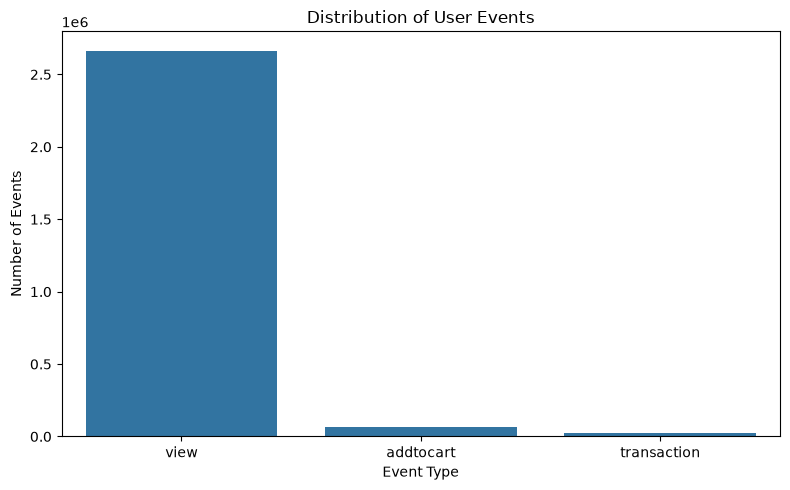

In [17]:
plt.figure(figsize=(8, 5))
sns.countplot(data=events, x="event", order=event_counts.index)
plt.title("Distribution of User Events")
plt.xlabel("Event Type")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

## 9. User and Product Analysis

In [18]:
unique_users = events["visitorid"].nunique()
unique_items = events["itemid"].nunique()

print("Unique users:", unique_users)
print("Unique items:", unique_items)
print("Total events:", len(events))

Unique users: 1407580
Unique items: 235061
Total events: 2755641


In [19]:
events_per_user = events.groupby("visitorid").size()
events_per_item = events.groupby("itemid").size()

print("Average events per user:", events_per_user.mean())
print("Median events per user:", events_per_user.median())
print("Average events per item:", events_per_item.mean())
print("Median events per item:", events_per_item.median())

Average events per user: 1.9577153696415124
Median events per user: 1.0
Average events per item: 11.723088900328
Median events per item: 3.0


## 10. Temporal Analysis

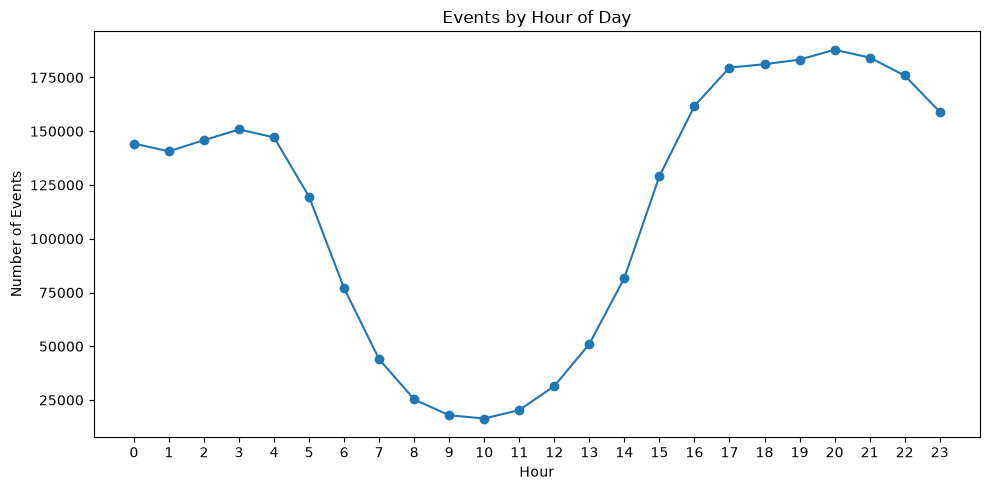

In [20]:
hourly_events = events["hour"].value_counts().sort_index()

plt.figure(figsize=(10, 5))
plt.plot(hourly_events.index, hourly_events.values, marker="o")
plt.title("Events by Hour of Day")
plt.xlabel("Hour")
plt.ylabel("Number of Events")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

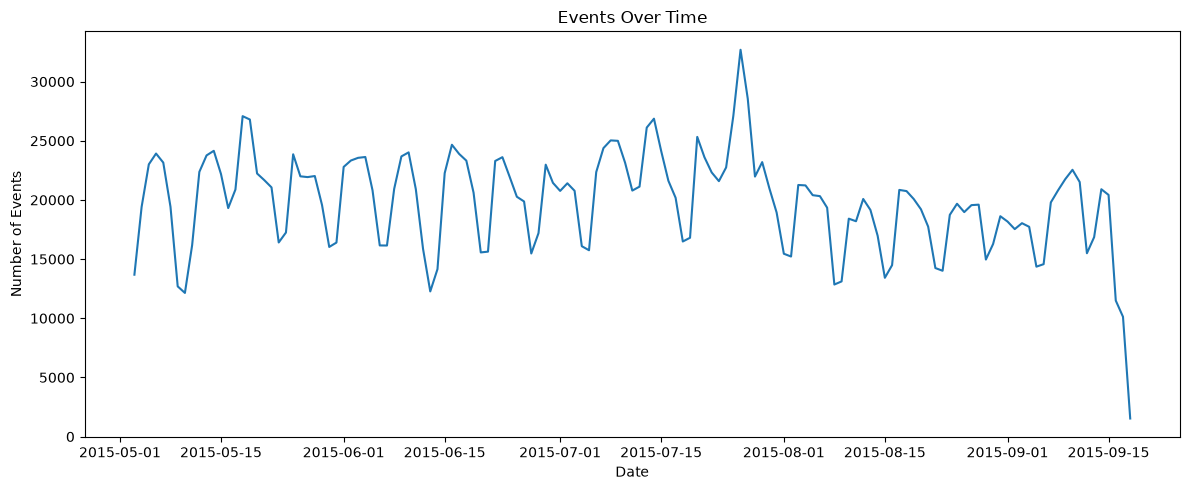

In [21]:
daily_events = events.groupby("date").size()

plt.figure(figsize=(12, 5))
plt.plot(pd.to_datetime(daily_events.index), daily_events.values)
plt.title("Events Over Time")
plt.xlabel("Date")
plt.ylabel("Number of Events")
plt.tight_layout()
plt.show()

## 11. Interaction Weighting

We use an initial heuristic to represent the strength of user intent:

- `view` → 1
- `addtocart` → 3
- `transaction` → 5

These values are initial assumptions and will be evaluated later.

In [22]:
event_weights = {
    "view": 1,
    "addtocart": 3,
    "transaction": 5
}

events["interaction_weight"] = events["event"].map(event_weights)

events[["event", "interaction_weight"]].drop_duplicates().sort_values("interaction_weight")

,event,interaction_weight
0,view,1
17,addtocart,3
130,transaction,5


## 12. Build User-Item Interaction Dataset

In [23]:
event_strength = {
    "view": 1,
    "addtocart": 2,
    "transaction": 3
}

events["event_strength"] = events["event"].map(event_strength)

In [24]:
interaction_details = (
    events.groupby(["visitorid", "itemid"], as_index=False)
    .agg(
        interaction_score=("interaction_weight", "sum"),
        interaction_count=("event", "count"),
        strongest_event=("event_strength", "max"),
        last_interaction=("datetime", "max")
    )
)

strength_to_event = {
    1: "view",
    2: "addtocart",
    3: "transaction"
}

interaction_details["strongest_event"] = (
    interaction_details["strongest_event"].map(strength_to_event)
)

interactions = interaction_details.copy()
interactions.head()

,visitorid,itemid,interaction_score,interaction_count,strongest_event,last_interaction
0,0,67045,1,1,view,2015-09-11 20:55:17.175
1,0,285930,1,1,view,2015-09-11 20:49:49.439
2,0,357564,1,1,view,2015-09-11 20:52:39.591
3,1,72028,1,1,view,2015-08-13 17:46:06.444
4,2,216305,2,2,view,2015-08-07 18:17:43.170


## 13. Interaction Statistics

In [25]:
print("Total user-item interactions:", len(interactions))
print("Unique users:", interactions["visitorid"].nunique())
print("Unique items:", interactions["itemid"].nunique())
print("Average interactions per user:", interactions.groupby("visitorid").size().mean())
print("Average interactions per item:", interactions.groupby("itemid").size().mean())

Total user-item interactions: 2145179
Unique users: 1407580
Unique items: 235061
Average interactions per user: 1.5240192386933602
Average interactions per item: 9.126052386401827


## 14. User-Item Matrix Sparsity

In [26]:
num_users = interactions["visitorid"].nunique()
num_items = interactions["itemid"].nunique()
num_interactions = len(interactions)

total_possible_interactions = num_users * num_items
sparsity = 1 - (num_interactions / total_possible_interactions)

print(f"Users: {num_users:,}")
print(f"Items: {num_items:,}")
print(f"Observed user-item interactions: {num_interactions:,}")
print(f"Possible user-item interactions: {total_possible_interactions:,}")
print(f"Sparsity: {sparsity:.4%}")

Users: 1,407,580
Items: 235,061
Observed user-item interactions: 2,145,179
Possible user-item interactions: 330,867,162,380
Sparsity: 99.9994%


## 15. Save Processed Data

Raw data remains unchanged. Cleaned event data and aggregated user-item interactions are stored separately for downstream modeling.

In [27]:
os.makedirs("../data/processed", exist_ok=True)

events.to_parquet(
    "../data/processed/events_clean.parquet",
    index=False
)

interactions.to_parquet(
    "../data/processed/interactions.parquet",
    index=False
)

print("Processed datasets saved successfully.")

Processed datasets saved successfully.


## 16. EDA Summary

Record the important findings from this notebook after reviewing the outputs above.

Suggested points to document:

- total number of events
- number of unique users
- number of unique items
- distribution of views, add-to-cart events, and transactions
- average and median interactions per user
- temporal patterns
- interaction sparsity
- data-quality issues discovered
- preprocessing decisions and their justification

These findings will determine how the collaborative filtering and content-based recommendation models are designed.